# 矩阵乘法

本教程将编写一个简短的高性能 FP16 矩阵乘法内核，目标是达到与 cuBLAS 或 rocBLAS 相当的性能。

你将学习：

- 块级矩阵乘法。
- 多维指针运算。
- 通过调整程序实例的执行顺序提高 L2 缓存命中率。
- 自动性能调优。

---

来源：[Triton 官方教程](https://triton-lang.org/main/getting-started/tutorials/03-matrix-multiplication.html)，版本为 2026-10-16 下载的官网 main 文档。

中文练习版：保留说明与公式；原有代码单元及说明中的独立代码块均保留为空白代码框；移除代码、运行输出、测量结果与图表。空白框供自行填写，未运行教程。原文许可见 [TRITON-LICENSE.txt](TRITON-LICENSE.txt)。

## 动机

矩阵乘法是现代高性能计算系统的重要基础操作，但优化难度很高，因此通常由硬件厂商在 cuBLAS 等内核库中提供实现。

这类库往往是专有的，难以针对现代深度学习工作负载定制，例如融合激活函数。本教程介绍如何使用 Triton 实现便于定制和扩展的高效矩阵乘法。

下面的代码框对应将形状为 (M, K) 和 (K, N) 的矩阵相乘的分块算法。

In [ ]:
# for m in range(0, M, BLOCK_SIZE_M)
# 遍历 0~M, 步长为 BLOCK_SIZE_M

# Do in parallel
for m in range(0, M, BLOCK_SIZE_M):
    # Do in parallel
    for n in range(0, N, BLOCK_SIZE_N):
        acc = zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), dtype=float32)
        for k in range(0, K, BLOCK_SIZE_K):
            # 从 m 行开始, 取 BLOCK_SIZE_M 行, 从 k 列开始, 取 BLOCK_SIZE_K 列
            a = A[m : m+BLOCK_SIZE_M, k : k+BLOCK_SIZE_K]
            b = B[k : k+BLOCK_SIZE_K, n : n+BLOCK_SIZE_N]
            acc += dot(a, b)
        C[m : m+BLOCK_SIZE_M, n : n + BLOCK_SIZE_N] = acc

外层双重循环的每次迭代由一个独立的 Triton 程序实例完成。

## 计算内核

上述算法在 Triton 中的实现相对直接。主要难点是计算内层循环中 A 和 B 的数据块所在的内存地址，这需要多维指针运算。

### 指针运算

对于按行优先存储的二维张量 X，元素 $(i,j)$ 的地址等于基地址加上两个维度各自的偏移量：

$$
\operatorname{addr}(X_{i,j})=\operatorname{base}(X)+i\,s_i+j\,s_j
$$

其中 $s_i$ 和 $s_j$ 表示对应维度的步长。下面的代码框对应 A 和 B 子块的指针构造伪代码。

In [ ]:
&A[m : m+BLOCK_SIZE_M, k:k+BLOCK_SIZE_K] = a_ptr + (m : m+BLOCK_SIZE_M)[:, NONE]*A.stride(0) + (k : k+BLOCK_SIZE_K)[None, :]*A.stride(1);
&B[k : k+BLOCK_SIZE_K, n:n+BLOCK_SIZE_N] = b_ptr + (k : k+BLOCK_SIZE_K)[:, NONE]*B.stride(0) + (n : n+BLOCK_SIZE_N)[None, :]*B.stride(1);

由此可以在 K 方向的起点初始化两个数据块的指针。如果 M 或 N 不是相应块大小的整数倍，需要额外的取模处理，以填入不会影响最终结果的值。K 方向的边界稍后通过带掩码的加载处理。

In [ ]:
offs_am = (pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)) % M 
offs_bn = (pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)) % N
offs_k = tl.arange(0, BLOCK_SIZE_K)
a_ptrs = a_ptr + (offs_am[:, None] * stride_am + offs_k [None, :] * stride_ak)
b_ptrs = b_ptr + (offs_k [:, None] * stride_bk + offs_bn[None, :] * stride_bn)

随后，在内层循环中推进指针。

In [ ]:
a_ptrs += BLOCK_SIZE_K * stride_ak;
b_ptrs += BLOCK_SIZE_K * stride_bk;

### L2 缓存优化

每个程序实例计算输出矩阵 C 中一个大小为 BLOCK_SIZE_M × BLOCK_SIZE_N 的块。

块的计算顺序会影响 L2 缓存命中率。简单的行优先顺序不一定能带来理想效果。

In [ ]:
pid = tl.program_id(axis=0)
grid_n = tl.cdiv(N, BLOCK_SIZE_N)
pid_m = pid // grid_n
pid_n = pid % grid_n

一种改进方式是采用有利于数据复用的块启动顺序：先把若干行的块组成一个大组，再切换到下一列。

In [ ]:
pid = tl.program_id(axis=0)


原文用每个矩阵由 9 × 9 个块组成的例子说明：计算前 9 个输出块时，行优先顺序需要向 SRAM 加载 90 个块，而分组顺序只需加载 54 个块。这些数字属于算法示例，并非本地测量结果。

原文还给出了顺序对比示意图及特定硬件上的性能结果，本笔记省略这些图表和测量数值。

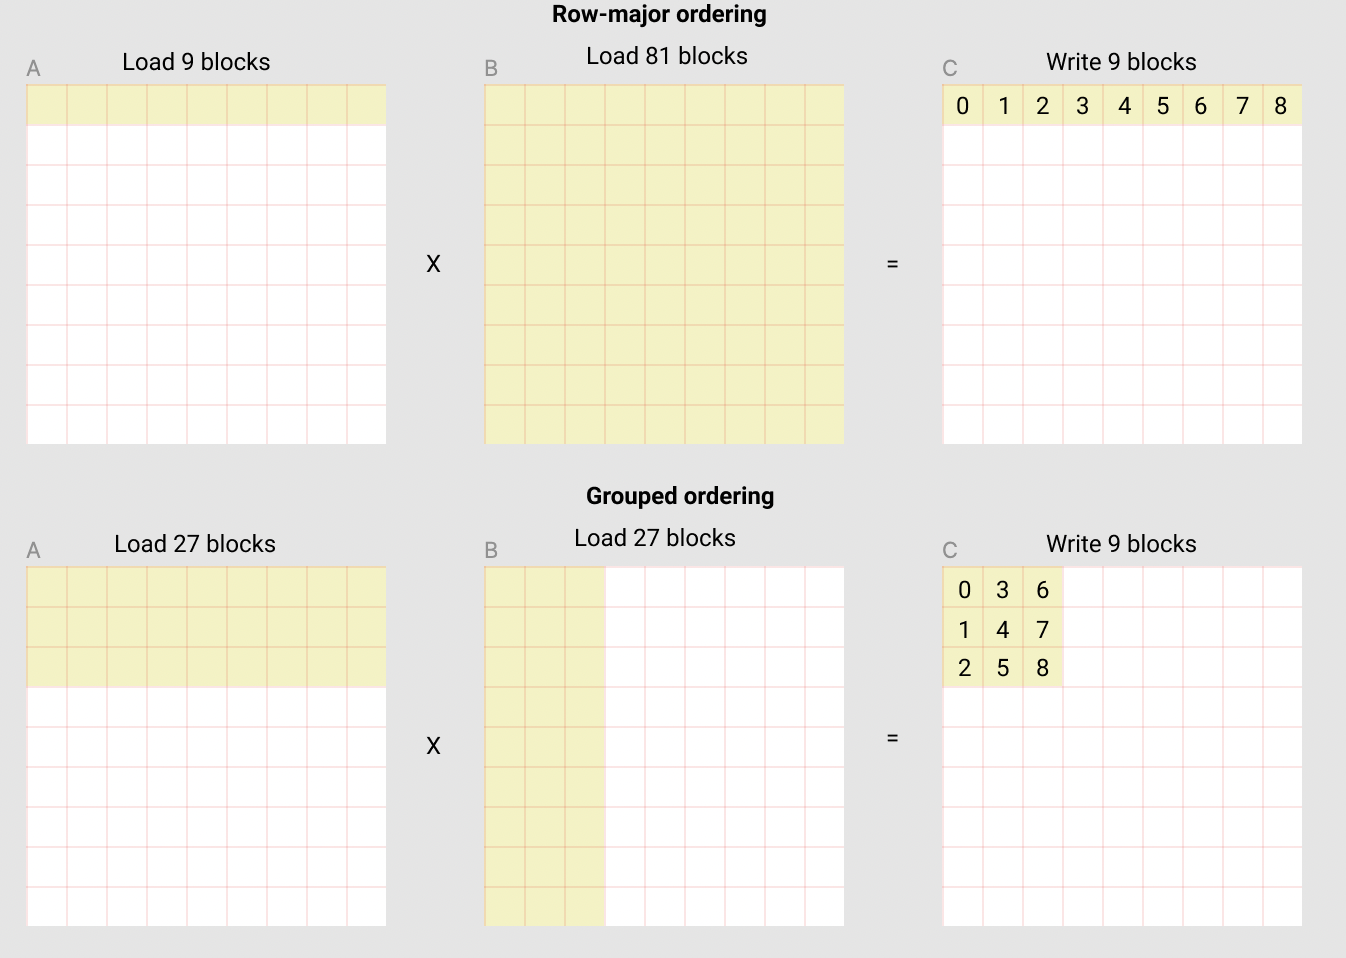

## 完整实现

In [ ]:
import torch

import triton
import triton.language as tl

DEVICE = triton.runtime.driver.active.get_active_torch_device()

def get_autotune_config():
    return [
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=3, num_warps=8),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 32, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 32, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=5, num_warps=2),
        triton.Config({'BLOCK_SIZE_M': 32, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 32, 'GROUP_SIZE_M': 8}, num_stages=5, num_warps=2),
        # 以下包含适合 FP8 输入的候选配置，与官方教程保持一致。
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=3, num_warps=8),
        triton.Config({'BLOCK_SIZE_M': 256, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=3, num_warps=8),
        triton.Config({'BLOCK_SIZE_M': 256, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 256, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 128, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 64, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 64, 'BLOCK_SIZE_N': 128, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
        triton.Config({'BLOCK_SIZE_M': 128, 'BLOCK_SIZE_N': 32, 'BLOCK_SIZE_K': 64, 'GROUP_SIZE_M': 8}, num_stages=4, num_warps=4),
    ]


@triton.autotune(
    configs=get_autotune_config(),
    key=['M', 'N', 'K'],
)
@triton.jit
def matmul_kernel(
    a_ptr, b_ptr, c_ptr,
    M, N, K,
    stride_am, stride_ak,
    stride_bk, stride_bn,
    stride_cm, stride_cn,
    BLOCK_SIZE_M: tl.constexpr, BLOCK_SIZE_N: tl.constexpr, BLOCK_SIZE_K: tl.constexpr,
    GROUP_SIZE_M: tl.constexpr,
    ACTIVATION: tl.constexpr,
):
    pid = tl.program_id(axis=0)
    # M 分成 num_pid_m 个 BLOCK_SIZE_M
    num_pid_m = tl.cdiv(M, BLOCK_SIZE_M)
    # N 分成 num_pid_n 个 BLOCK_SIZE_N
    num_pid_n = tl.cdiv(N, BLOCK_SIZE_N)
    # 一个完整的分组里, 一共有多少个 program
    num_pid_in_group = GROUP_SIZE_M * num_pid_n
    group_id = pid // num_pid_in_group
    first_pid_m = group_id * GROUP_SIZE_M
    group_size_m = min(num_pid_m - first_pid_m, GROUP_SIZE_M)
    pid_m = first_pid_m + ((pid % num_pid_in_group) % group_size_m)
    pid_n = (pid % num_pid_in_group) // group_size_m

    tl.assume(pid_m >= 0)
    tl.assume(pid_n >= 0)
    tl.assume(stride_am > 0)
    tl.assume(stride_ak > 0)
    tl.assume(stride_bn > 0)
    tl.assume(stride_bk > 0)
    tl.assume(stride_cm > 0)
    tl.assume(stride_cn > 0)

    offs_am = (pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)) % M 
    offs_bn = (pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)) % N
    offs_k = tl.arange(0, BLOCK_SIZE_K)
    a_ptrs = a_ptr + (offs_am[:, None] * stride_am + offs_k[None, :] * stride_ak)
    b_ptrs = b_ptr + (offs_k[:, None] * stride_bk + offs_bn[None, :] * stride_bn)

    accumulator = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), dtype=tl.float32)
    for k in range(0, tl.cdiv(K, BLOCK_SIZE_K)):
        # Load the next block of A and B, generate a mask by checking the K dimension.
        # If it is out of bounds, set it to 0.
        a = tl.load(a_ptrs, mask=offs_k[None, :] < K - k * BLOCK_SIZE_K, other=0.0)
        b = tl.load(b_ptrs, mask=offs_k[:, None] < K - k * BLOCK_SIZE_K, other=0.0)
        # We accumulate along the K dimension.
        accumulator = tl.dot(a, b, accumulator)
        # Advance the ptrs to the next K block.
        a_ptrs += BLOCK_SIZE_K * stride_ak
        b_ptrs += BLOCK_SIZE_K * stride_bk
    # You can fuse arbitrary activation functions here
    # while the accumulator is still in FP32!
    if ACTIVATION == "leaky_relu":
        accumulator = leaky_relu(accumulator)
    c = accumulator.to(tl.float16)

    offs_cm = pid_m * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
    offs_cn = pid_n * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)
    c_ptrs = c_ptr + stride_cm * offs_cm[:, None] + stride_cn * offs_cn[None, :]
    c_mask = (offs_cm[:, None] < M) & (offs_cn[None, :] < N)
    tl.store(c_ptrs, c, mask=c_mask)

@triton.jit
def leaky_relu(x):
    return tl.where(x >= 0, x, 0.01 * x)

现在可以创建一个只接受两个输入张量的包装函数，依次检查形状约束、分配输出张量并启动上述内核。

In [ ]:
def matmul(a, b, activation=""):
    # Check constraints.
    assert a.shape[1] == b.shape[0], "Incompatible dimensions"
    assert a.is_contiguous(), "Matrix A must be contiguous"
    M, K = a.shape
    K, N = b.shape
    # Allocates output.
    c = torch.empty((M, N), device=a.device, dtype=torch.float16)
    # 1D launch kernel where each block gets its own program.
    grid = lambda META: (triton.cdiv(M, META['BLOCK_SIZE_M']) * triton.cdiv(N, META['BLOCK_SIZE_N']), )
    matmul_kernel[grid](
        a, b, c,  #
        M, N, K,  #
        a.stride(0), a.stride(1),  #
        b.stride(0), b.stride(1),  #
        c.stride(0), c.stride(1),  #
        ACTIVATION=activation  #
    )
    return c

## 单元测试

将自定义矩阵乘法与 PyTorch 的原生实现进行比较；原教程在这里使用 cuBLAS 作为参考。

In [ ]:
torch.manual_seed(0)
a = torch.rand((512, 512), device=DEVICE, dtype=torch.float16) - 0.5
b = torch.rand((512, 512), device=DEVICE, dtype=torch.float16) - 0.5
triton_output = matmul(a, b)
torch_output = torch.matmul(a, b)
print(f"triton_output_with_fp16_inputs={triton_output}")
print(f"torch_output_with_fp16_inputs={torch_output}")

if torch.allclose(triton_output, torch_output, atol=1e-2, rtol=0):
    print("✅ Triton and Torch match")
else:
    print("❌ Triton and Torch differ")

torch.manual_seed(0)
a = torch.randn((512, 512), device=DEVICE, dtype=torch.float16)
b = torch.randn((512, 512), device=DEVICE, dtype=torch.float16)
a = a.to(torch.float8_e5m2)
# pre-transpose b for efficiency.
b = b.T
b = b.to(torch.float8_e5m2)
triton_output = matmul(a, b)
torch_output = torch.matmul(a.to(torch.float16), b.to(torch.float16))
print(f"triton_output_with_fp8_inputs={triton_output}")
print(f"torch_output_with_fp8_inputs={torch_output}")
if torch.allclose(triton_output, torch_output, atol=0.125, rtol=0):
    print("✅ Triton and Torch match")
else:
    print("❌ Triton and Torch differ")

## 性能基准测试

### 方阵性能

比较自定义内核与 cuBLAS 或 rocBLAS 的性能。这里主要测试方阵，也可以调整测试范围，研究其他矩阵形状。

In [ ]:
ref_lib = 'cuBLAS'

configs = []
for fp8_inputs in [False, True]:
    configs.append(
        triton.testing.Benchmark(
            x_names=["M", "N", "K"],  # Argument names to use as an x-axis for the plot
            x_vals=[128 * i for i in range(2, 33)],  # Different possible values for `x_name`
            line_arg="provider",  # Argument name whose value corresponds to a different line in the plot
            # Possible values for `line_arg`
            # Don't compare to cublas for fp8 cases as torch.matmul doesn't support fp8 at the moment.
            line_vals=["triton"] if fp8_inputs else [ref_lib.lower(), "triton"],  # Label name for the lines
            line_names=["Triton"] if fp8_inputs else [ref_lib, "Triton"],  # Line styles
            styles=[("green", "-"), ("blue", "-")],
            ylabel="TFLOPS",  # Label name for the y-axis
            plot_name="matmul-performance-" +
            ("fp16" if not fp8_inputs else "fp8"),  # Name for the plot, used also as a file name for saving the plot.
            args={"fp8_inputs": fp8_inputs},
        ))


@triton.testing.perf_report(configs)
def benchmark(M, N, K, provider, fp8_inputs):
    a = torch.randn((M, K), device=DEVICE, dtype=torch.float16)
    b = torch.randn((K, N), device=DEVICE, dtype=torch.float16)
    if fp8_inputs:
        a = a.to(torch.float8_e5m2)
        # 保持 (K, N) 形状，转换为列优先布局。
        b = b.T.contiguous().T.to(torch.float8_e5m2)
    quantiles = [0.5, 0.2, 0.8]
    if provider == ref_lib.lower():
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: torch.matmul(a, b), quantiles=quantiles)
    if provider == 'triton':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: matmul(a, b), quantiles=quantiles)
    perf = lambda ms: 2 * M * N * K * 1e-12 / (ms * 1e-3)
    return perf(ms), perf(max_ms), perf(min_ms)


benchmark.run(show_plots=True, print_data=True)
